# AutoML from Scratch: Search Spaces, Bandits, Bayesian Optimisation and Ensembles

> **Who is this for:** you have used a tuner or AutoML tool (Optuna, H2O, TPOT; see [`01_automl`](01_automl.ipynb)) and want to know what is inside: how hyperparameter search actually works, why some methods are far more efficient than others, and how to avoid fooling yourself with an over-tuned model. It is also MS-level preparation for "AutoML" or "Advanced ML" courses and for ML-engineer interviews.
>
> **What you will learn:**
> - The **CASH** problem (Combined Algorithm Selection and Hyperparameter optimisation) and how to design a **search space** (log scales, conditional parameters)
> - **Random vs grid search** and the "low effective dimensionality" argument
> - **Successive halving** and **Hyperband** implemented from scratch (budget = training-set size), compared with sklearn's `HalvingRandomSearchCV`
> - **Bayesian optimisation from scratch**: a Gaussian-process surrogate with **expected improvement**, compared with random search and a **TPE**-style method
> - **Early stopping** with learning-curve extrapolation
> - **Ensemble selection** (Caruana et al., 2004) over the models tried
> - **Meta-learning warm starts** from dataset meta-features
> - A toy **neural architecture search** in PyTorch, with cost accounting
> - Pitfalls: **overfitting the validation set**, **nested cross-validation**, and honest **compute-budget reporting**
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb); [model evaluation and cross-validation](../../03_Machine_Learning/06_model_evaluation/01_model_evaluation.ipynb) and [hyperparameter optimisation basics](../../03_Machine_Learning/06_model_evaluation/02_hyperparameter_optimization.ipynb); [Gaussian processes in `14_Mathematics/07_bayesian_ml`](../../14_Mathematics/07_bayesian_ml.ipynb); [`01_automl`](01_automl.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU, no API key, no internet (the digits dataset ships with scikit-learn). The whole notebook runs in about 2–3 minutes.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows Hutter, Kotthoff & Vanschoren (eds.), *Automated Machine Learning: Methods, Systems, Challenges* (2019, free online), and the original papers cited in each section.

## Explained simply

Every machine-learning model has **knobs** (hyperparameters): how deep a tree grows, how strongly to regularise, how fast to learn. **AutoML** is a robot that turns the knobs for you and picks the best model. The trouble is that each try costs time (you must train a model), so the robot has to be smart about which knobs to try.

Think of tuning a radio in a car: you do not try every frequency one by one; you sweep quickly, notice where the signal gets clearer, and fine-tune there. That is **Bayesian optimisation**. Or think of a talent show with 27 singers: you hear 30 seconds from each, keep the best third for a full song, then keep the best third again for the final. That is **successive halving**: spend little on the bad options and a lot on the promising ones.

**Tiny example.** You can bake 9 test cakes. A **grid** tries 3 oven temperatures × 3 baking times. If only temperature really matters, you have learned about just 3 temperatures. **Random** choices give 9 different temperatures (and 9 different times), so you explore the important knob 3 times more thoroughly for the same 9 cakes.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Hyperparameter search | try settings of the knobs and keep the best | tuning learning rates for neural nets, Kaggle competitions |
| Successive halving / Hyperband | give every option a small trial, then more time only to the winners | Optuna and Ray Tune pruners, large-scale training sweeps |
| Bayesian optimisation | use past tries to guess where the next good setting is | AutoML services, tuning expensive experiments in labs |

### How this notebook is different from `01_automl`
[`01_automl`](01_automl.ipynb) shows how to *use* AutoML tools (Optuna pruning, H2O, TPOT, NAS libraries). Here we **build the algorithms ourselves** on small, fast problems, measure them against each other at equal budgets, and study the statistical traps. The GP regression equations are the same as in [`14_Mathematics/07_bayesian_ml`](../../14_Mathematics/07_bayesian_ml.ipynb) and the [industry GP notebook](../../03_Machine_Learning/04_uncommon_models/02_industry_gaussian_process_process_optimization.ipynb).

## Table of contents
1. The CASH problem and search-space design
2. Random search vs grid search
3. Successive halving and Hyperband
4. Bayesian optimisation: GP + expected improvement, and TPE
5. Early stopping and learning-curve extrapolation
6. Ensemble selection
7. Meta-learning warm starts
8. A toy neural architecture search
9. Pitfalls: validation overfitting, nested CV, budget reporting
10. How this connects to modern AI
11. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import os
os.environ.setdefault("OMP_NUM_THREADS", "2")     # be polite on shared machines
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
import sys, math, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)
np.random.seed(42)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titleweight": "bold", "figure.dpi": 100,
})
pd.set_option("display.width", 140)
pd.set_option("display.precision", 4)
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

from scipy.stats import norm
from scipy.optimize import curve_fit
from sklearn.datasets import load_digits, make_classification
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.experimental import enable_halving_search_cv  # noqa: F401  (enables HalvingRandomSearchCV)
from sklearn.model_selection import HalvingRandomSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.calibration import CalibratedClassifierCV
import torch, torch.nn as nn
torch.set_num_threads(2)
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # tiny budgets do not always converge, on purpose

digits = load_digits()
X_all, y_all = digits.data / 16.0, digits.target                  # pixels 0..16 -> 0..1 (no fitted scaler, no leakage)
X_tr, X_rest, y_tr, y_rest = train_test_split(X_all, y_all, train_size=1000, stratify=y_all, random_state=0)
X_val, X_te, y_val, y_te = train_test_split(X_rest, y_rest, train_size=400, stratify=y_rest, random_state=0)
print("train / validation / test sizes:", len(X_tr), len(X_val), len(X_te))
SEARCH_LOG = []                                                     # every model fit, for compute accounting

Python 3.12.3 | numpy 2.4.6 | pandas 2.3.3


train / validation / test sizes: 1000 400 397


## 1. The CASH problem and search-space design

> 💬 **In plain English:** decide which models and which knob settings the robot is allowed to try, and on what scale.

**Definition (Thornton et al., 2013).** Given algorithms A⁽¹⁾..A⁽ᵏ⁾ with hyperparameter spaces Λ⁽¹⁾..Λ⁽ᵏ⁾, **CASH** finds
$$A^*_{\lambda^*} \in \arg\min_{j,\;\lambda\in\Lambda^{(j)}} \; \mathcal L\big(A^{(j)}_\lambda,\; D_{\text{train}},\; D_{\text{valid}}\big).$$
The choice of algorithm is itself a (categorical) hyperparameter at the root of a **tree-structured** space: `gamma` only exists if the algorithm is an RBF SVM. Such parameters are called **conditional**.

**Search-space design rules**

| Kind of knob | Example | Sample it… | Why |
|---|---|---|---|
| scale parameter spanning orders of magnitude | C, learning rate, weight decay, gamma | **log-uniformly** | the difference between 0.001 and 0.01 matters as much as between 10 and 100 |
| count | trees, neighbours, layers | integer, often log-scaled | |
| fraction | dropout, max_features, subsample | uniform on [a, b] | |
| choice | kernel, activation, weighting | categorical | |
| conditional | gamma (only for SVC), max_depth (only for trees) | only when the parent choice is active | avoids wasting trials on irrelevant knobs |

  algo         C   gamma  max_features  min_samples_leaf  n_neighbors  weights
0  svc  565.3514  0.0004           NaN               NaN          NaN      NaN
1   rf       NaN     NaN        0.5718               3.0          NaN      NaN
2  svc    1.3081  0.2046           NaN               NaN          NaN      NaN
3  svc    5.5972  0.0001           NaN               NaN          NaN      NaN
4  svc   58.5552  0.0142           NaN               NaN          NaN      NaN
5  knn       NaN     NaN           NaN               NaN         10.0  uniform


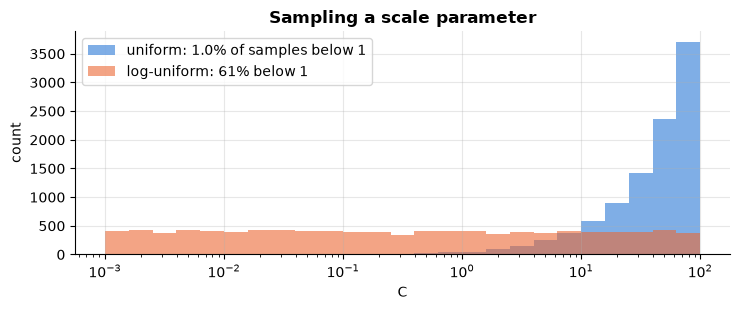

In [2]:
SPACE = {
    "logreg": {"C": ("log", 1e-3, 1e2)},
    "svc":    {"C": ("log", 1e-2, 1e3), "gamma": ("log", 1e-4, 1e0)},
    "rf":     {"max_features": ("float", 0.05, 0.6), "min_samples_leaf": ("int", 1, 10)},
    "knn":    {"n_neighbors": ("int", 1, 30), "weights": ("cat", ["uniform", "distance"])},
}

def sample_param(spec, r):
    kind = spec[0]
    if kind == "log":
        return float(np.exp(r.uniform(np.log(spec[1]), np.log(spec[2]))))   # log-uniform
    if kind == "float":
        return float(r.uniform(spec[1], spec[2]))
    if kind == "int":
        return int(r.integers(spec[1], spec[2] + 1))
    return str(r.choice(spec[1]))

def sample_config(r, algos=None):
    algo = str(r.choice(algos or list(SPACE)))               # root choice: the algorithm
    return {"algo": algo, **{k: sample_param(v, r) for k, v in SPACE[algo].items()}}   # its conditional params

def build_model(cfg):
    p = {k: v for k, v in cfg.items() if k != "algo"}
    if cfg["algo"] == "logreg":
        return LogisticRegression(max_iter=300, **p)
    if cfg["algo"] == "svc":
        return SVC(**p)
    if cfg["algo"] == "rf":
        return RandomForestClassifier(n_estimators=40, random_state=0, n_jobs=1, **p)
    return KNeighborsClassifier(**p)

def evaluate(cfg, n_train=None, seed=0, tag=""):
    """Fit on the first n_train training points (the 'budget'), return validation accuracy."""
    n = n_train or len(X_tr)
    idx = np.random.default_rng(seed).permutation(len(X_tr))[:n]
    t0 = time.perf_counter()
    model = build_model(cfg).fit(X_tr[idx], y_tr[idx])
    acc = model.score(X_val, y_val)
    SEARCH_LOG.append({"tag": tag, "algo": cfg["algo"], "n_train": n, "val_acc": acc, "seconds": time.perf_counter() - t0})
    return acc

r1 = np.random.default_rng(1)
print(pd.DataFrame([sample_config(r1) for _ in range(6)]).to_string())

# Why log scales: sample C in [1e-3, 1e2] uniformly vs log-uniformly
u = r1.uniform(1e-3, 1e2, 10000); lu = np.exp(r1.uniform(np.log(1e-3), np.log(1e2), 10000))
fig, ax = plt.subplots(figsize=(7.5, 3.2))
bins = np.logspace(-3, 2, 26)
ax.hist(u, bins=bins, alpha=0.6, label=f"uniform: {np.mean(u < 1):.1%} of samples below 1")
ax.hist(lu, bins=bins, alpha=0.6, label=f"log-uniform: {np.mean(lu < 1):.0%} below 1")
ax.set_xscale("log"); ax.set_xlabel("C"); ax.set_ylabel("count"); ax.set_title("Sampling a scale parameter"); ax.legend()
plt.tight_layout(); plt.show()

**What just happened?** Each sampled configuration first picks an algorithm and then only that algorithm's hyperparameters (the NaN cells are conditional parameters that do not exist for that algorithm). Sampling C uniformly on [0.001, 100] puts only about 1% of the trials below 1, although three of the five decades of the range lie there; a log-uniform prior spreads trials evenly over the decades.

> ⚠️ **Common mistake:** a search space that is too narrow (the best value sits on the boundary) or on the wrong scale. After every search, plot the best trials against each hyperparameter: if they pile up at an edge, widen the range.

## 2. Random search vs grid search

> 💬 **In plain English:** random tries cover the knobs that matter better than a neat grid does.

**Bergstra & Bengio (2012)**: when only a few hyperparameters really matter (**low effective dimensionality**), a grid wastes most trials repeating the same values of the important ones. With a budget of n trials over d knobs, a grid tests only n^(1/d) distinct values per knob, while random search tests n distinct values of every knob.

First a synthetic function where we know the answer: `f(x, y) = g(x) + 0.05·h(y)`, where only x matters much and the optimum of g is a narrow peak.

grid (9 trials): best f = 0.055
random (9 trials, 2000 repeats): median best f = 0.677, P(best f > 0.5) = 0.59


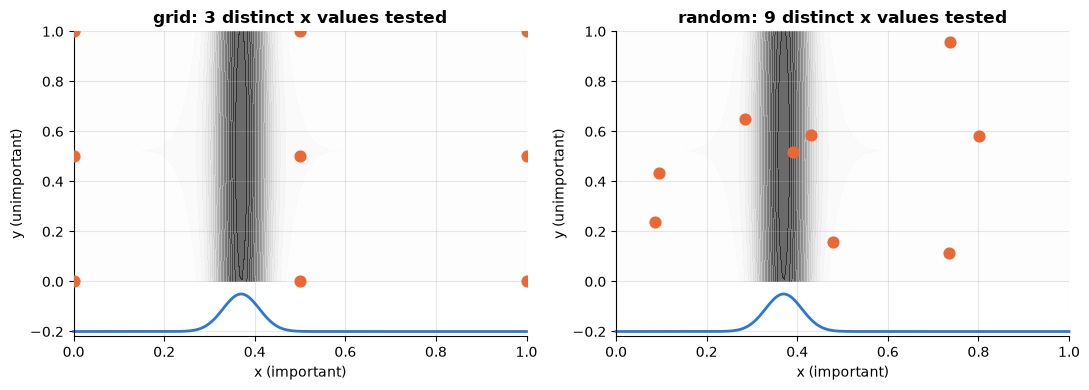

In [3]:
g_x = lambda x: np.exp(-(x - 0.37) ** 2 / (2 * 0.04 ** 2))        # important knob: a narrow peak at x = 0.37
h_y = lambda y: np.sin(3 * y)                                      # unimportant knob
f_xy = lambda x, y: g_x(x) + 0.05 * h_y(y)

grid_pts = np.array([(a, b) for a in np.linspace(0, 1, 3) for b in np.linspace(0, 1, 3)])   # 3 x 3 = 9 trials
best_grid = f_xy(*grid_pts.T).max()
best_rand = np.array([f_xy(*np.random.default_rng(s).random((9, 2)).T).max() for s in range(2000)])
print(f"grid (9 trials): best f = {best_grid:.3f}")
print(f"random (9 trials, 2000 repeats): median best f = {np.median(best_rand):.3f}, "
      f"P(best f > 0.5) = {np.mean(best_rand > 0.5):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
xx = np.linspace(0, 1, 200)
ex = np.random.default_rng(3).random((9, 2))
for a, pts, name in [(ax[0], grid_pts, "grid"), (ax[1], ex, "random")]:
    XX, YY = np.meshgrid(xx, xx)
    a.contourf(XX, YY, f_xy(XX, YY), levels=20, cmap="Greys", alpha=0.6)
    a.scatter(*pts.T, s=60, color=PALETTE[1], zorder=3)
    a.plot(xx, 0.15 * g_x(xx) - 0.2, color=PALETTE[0], clip_on=False)
    a.set_ylim(-0.22, 1); a.set_xlabel("x (important)"); a.set_ylabel("y (unimportant)")
    a.set_title(f"{name}: {len(np.unique(np.round(pts[:, 0], 6)))} distinct x values tested")
plt.tight_layout(); plt.show()

In [4]:
# The same comparison on a real model: RBF-SVM on digits, 16 trials in the box C in [1e-2, 1e3], gamma in [1e-4, 1]
grid_C, grid_g = np.logspace(-2, 3, 4), np.logspace(-4, 0, 4)
t0 = time.time()
grid_acc = max(evaluate({"algo": "svc", "C": c, "gamma": g_}, tag="grid") for c in grid_C for g_ in grid_g)
rand_acc = [max(evaluate(sample_config(np.random.default_rng(100 + s * 16 + i), ["svc"]), tag="random")
                for i in range(16)) for s in range(3)]
print(f"grid 4x4: best val acc {grid_acc:.4f} | random 16 trials (3 repeats): {np.round(rand_acc, 4)}  [{time.time() - t0:.1f}s]")

grid 4x4: best val acc 0.9900 | random 16 trials (3 repeats): [0.9925 0.995  0.9925]  [8.5s]


**What just happened?** On the synthetic function the 3 × 3 grid tests only x ∈ {0, 0.5, 1} and completely misses the peak at x = 0.37 (best f ≈ 0.05 from the minor y-term), while 9 random points test 9 different x values and often land near the peak. On the SVM the effect is milder (the good region is broad), but random search with the same 16 trials is at least as good as the grid, because the grid wastes trials re-testing the same 4 values of the important parameter, gamma.

> 🎓 **Exam / interview tip:** "Grid or random?" Random (or quasi-random such as Sobol sequences) for more than two knobs, because it degrades gracefully when some knobs do not matter and can be stopped at any time. Grids are fine for one or two knobs or for final, fine-grained sweeps.

## 3. Successive halving and Hyperband

> 💬 **In plain English:** give everyone a short audition, then more time only to the best.

**Intuition.** Most configurations are bad, and you can often tell early. Train many configurations **cheaply** (small budget: few epochs, few trees, or a small subset of data), keep the best fraction 1/η, give the survivors η times more budget, and repeat.

**Successive halving (SH)** (Jamieson & Talwalkar, 2016) with n configurations, minimum budget r and reduction factor η:

| rung i | configurations alive | budget each |
|---|---|---|
| 0 | n | r |
| 1 | ⌊n/η⌋ | r·η |
| 2 | ⌊n/η²⌋ | r·η² |
| … | … | up to R |

**The n-vs-r dilemma.** For a fixed total budget, SH must choose between many configurations with a small starting budget (risk: killing a slow starter) and few configurations with a large budget. **Hyperband** (Li et al., 2018) hedges by running several SH **brackets** with different trade-offs: with `s_max = ⌊log_η(R/r_min)⌋` and `B = (s_max + 1)·R`, bracket s starts `n = ⌈B/R · η^s/(s+1)⌉` configurations at budget `R·η^(−s)`.

Here the **budget is the number of training examples** (out of 1000), so a cheap trial is a model fitted on a small subset.

In [5]:
N_TRAIN = len(X_tr)
def successive_halving(configs, r_min, eta=3, R=N_TRAIN, seed=0, tag="SH"):
    """Returns the best config, its score at the final rung, and the full trace."""
    alive = list(range(len(configs)))
    budget = r_min
    trace = []
    while True:
        scores = {i: evaluate(configs[i], n_train=int(budget), seed=seed, tag=tag) for i in alive}
        trace += [(i, budget, s) for i, s in scores.items()]
        if budget >= R or len(alive) == 1:
            break
        keep = max(1, len(alive) // eta)
        alive = sorted(alive, key=lambda i: -scores[i])[:keep]           # promote the top 1/eta
        budget = min(R, budget * eta)
    best = max(alive, key=lambda i: scores[i])
    return best, scores[best], trace

def hyperband_brackets(R_units, eta=3):
    s_max = int(np.floor(np.log(R_units) / np.log(eta) + 1e-9))
    B = (s_max + 1) * R_units
    rows = []
    for s in range(s_max, -1, -1):
        n = int(np.ceil(B / R_units * eta ** s / (s + 1)))
        r = R_units * eta ** (-s)
        rows.append({"bracket s": s, "rungs (n_i, r_i)": [(int(n * eta ** (-i)), r * eta ** i) for i in range(s + 1)]})
    return rows

print("Hyperband schedule for R = 27 units, eta = 3 (1 unit = 1000/27 ≈ 37 training examples):")
for row in hyperband_brackets(27):
    print(f"  s={row['bracket s']}: " + ", ".join(f"{n} configs @ {r:g}" for n, r in row["rungs (n_i, r_i)"]))

Hyperband schedule for R = 27 units, eta = 3 (1 unit = 1000/27 ≈ 37 training examples):
  s=3: 27 configs @ 1, 9 configs @ 3, 3 configs @ 9, 1 configs @ 27
  s=2: 12 configs @ 3, 4 configs @ 9, 1 configs @ 27
  s=1: 6 configs @ 9, 2 configs @ 27
  s=0: 4 configs @ 27


In [6]:
def hyperband(R_units=27, eta=3, seed=0):
    r = np.random.default_rng(seed)
    unit = N_TRAIN / R_units
    results = []
    for row in hyperband_brackets(R_units, eta):
        n0, r0 = row["rungs (n_i, r_i)"][0]
        configs = [sample_config(r) for _ in range(n0)]
        best, score, trace = successive_halving(configs, r_min=r0 * unit, eta=eta, R=N_TRAIN, tag="hyperband")
        results.append((score, configs[best], trace))
    return max(results, key=lambda t: t[0]), results

t0 = time.time()
n_log0 = len(SEARCH_LOG)
(hb_score, hb_cfg, _), hb_all = hyperband(seed=0)
hb_cost = sum(e["n_train"] for e in SEARCH_LOG[n_log0:]) / N_TRAIN          # in "full-training equivalents"
hb_time = time.time() - t0
print(f"Hyperband: best val acc {hb_score:.4f} with {hb_cfg} | cost = {hb_cost:.1f} full fits, {hb_time:.1f}s")

# Random search with the SAME total budget (each trial is a full fit)
r_rs = np.random.default_rng(7)
rs_cfgs = [sample_config(r_rs) for _ in range(int(round(hb_cost)))]
t0 = time.time()
rs_scores = [evaluate(c, tag="random-full") for c in rs_cfgs]
print(f"Random search, {len(rs_cfgs)} full fits: best val acc {max(rs_scores):.4f} with {rs_cfgs[int(np.argmax(rs_scores))]} "
      f"| {time.time() - t0:.1f}s")
n_hb_configs = sum(row["rungs (n_i, r_i)"][0][0] for row in hyperband_brackets(27))
print(f"Hyperband looked at {n_hb_configs} configurations, random search at {len(rs_cfgs)}, for the same budget.")

Hyperband: best val acc 0.9950 with {'algo': 'svc', 'C': 2.686437827862912, 'gamma': 0.36136936901033967} | cost = 15.7 full fits, 2.7s


Random search, 16 full fits: best val acc 0.9800 with {'algo': 'svc', 'C': 96.68233792520697, 'gamma': 0.007442859338033209} | 1.5s
Hyperband looked at 49 configurations, random search at 16, for the same budget.


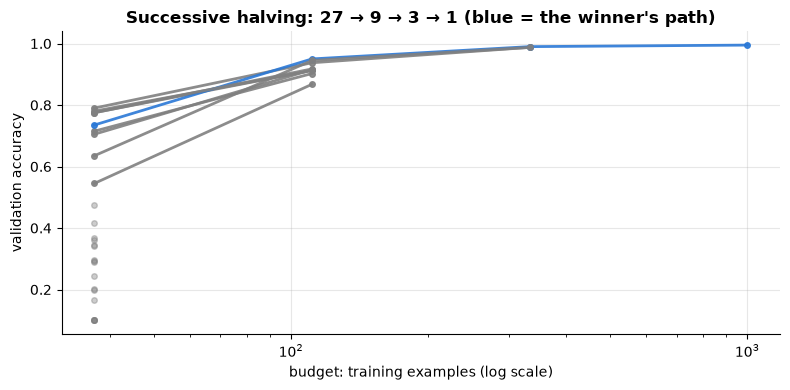

sklearn HalvingRandomSearchCV: 4 rungs, candidates per rung [27, 9, 3, 1], best CV acc 0.9769, val acc of refit model 0.9850 [1.0s]


In [7]:
# Visualise the most aggressive bracket (s = 3): 27 configs at 37 examples -> 9 -> 3 -> 1 at 1000
trace = hb_all[0][2]
fig, ax = plt.subplots(figsize=(8, 4))
tr = pd.DataFrame(trace, columns=["config", "budget", "val_acc"])
for cid, grp in tr.groupby("config"):
    ax.plot(grp["budget"], grp["val_acc"], "o-", color=PALETTE[0] if len(grp) == tr["budget"].nunique() else "grey",
            alpha=0.9 if len(grp) > 1 else 0.4, ms=4)
ax.set_xscale("log"); ax.set_xlabel("budget: training examples (log scale)"); ax.set_ylabel("validation accuracy")
ax.set_title("Successive halving: 27 → 9 → 3 → 1 (blue = the winner's path)"); plt.tight_layout(); plt.show()

# sklearn's implementation of the same idea (on one algorithm, with cross-validation instead of a fixed split)
from scipy.stats import loguniform
t0 = time.time()
hs = HalvingRandomSearchCV(SVC(), {"C": loguniform(1e-2, 1e3), "gamma": loguniform(1e-4, 1)}, n_candidates=27,
                           factor=3, resource="n_samples", min_resources=37, cv=3, random_state=0).fit(X_tr, y_tr)
print(f"sklearn HalvingRandomSearchCV: {hs.n_iterations_} rungs, candidates per rung {list(hs.n_candidates_)}, "
      f"best CV acc {hs.best_score_:.4f}, val acc of refit model {hs.best_estimator_.score(X_val, y_val):.4f} [{time.time() - t0:.1f}s]")

**What just happened?** Our Hyperband schedule reproduces the bracket table from Li et al. (for R = 27, η = 3): an aggressive bracket (27 configs from 37 examples), down to a conservative one (4 configs at full budget). For the same total compute as a handful of full fits, Hyperband examined several times more configurations, and found a model at least as good as random search's. In the rung plot, most configurations are dropped after the cheapest trial; only the promising ones receive more data. sklearn's `HalvingRandomSearchCV` runs the same schedule (with cross-validation at every rung).

**Complexity / cost.** One SH bracket costs about `(number of rungs) × n·r` budget units; Hyperband costs about `(s_max + 1)²·R` units in total, i.e. only a logarithmic factor more than evaluating a few configurations at full budget.

> ⚠️ **Common mistake:** using a budget that changes the *ranking* of configurations. Small subsets favour simple, strongly regularised models; a configuration that needs lots of data (a big forest, a low-regularisation net) can be eliminated too early. Hyperband's conservative brackets exist to limit this damage; asynchronous SH (**ASHA**) is the variant used in Ray Tune and Optuna for parallel workers.

## 4. Bayesian optimisation: GP + expected improvement, and TPE

> 💬 **In plain English:** learn a rough map of 'settings → error' from past tries and use it to pick the next try.

**Intuition.** Fit a cheap **surrogate model** of "hyperparameters → validation error" to the trials so far, and use it to decide where to try next, balancing **exploitation** (where the surrogate predicts low error) and **exploration** (where it is uncertain).

**GP surrogate.** A Gaussian process with a Matérn-5/2 kernel gives, at any point x, a predictive mean μ(x) and standard deviation σ(x) (same equations as [`14/07`](../../14_Mathematics/07_bayesian_ml.ipynb)).

**Expected improvement** (for minimisation, best observed value f*):
$$\mathrm{EI}(x) = \mathbb E\big[\max(f^* - f(x), 0)\big] = (f^* - \mu - \xi)\,\Phi(z) + \sigma\,\varphi(z),\qquad z = \frac{f^* - \mu - \xi}{\sigma}$$
EI is large where μ is low (exploit) **or** σ is large (explore). ξ ≥ 0 is a small exploration bonus.

**TPE** (Bergstra et al., 2011; used by Optuna and Hyperopt) models the problem the other way round: split past trials into the best γ fraction ("good") and the rest ("bad"), fit densities l(x) to the good and g(x) to the bad, and pick the candidate maximising **l(x)/g(x)**; this ratio is proportional to EI under TPE's model.

We tune an RBF-SVM's (log₁₀ C, log₁₀ γ) over a deliberately **wide** box, training on only 200 digits so each trial is cheap, 30 trials per method and 5 random seeds each. Because the problem is 2-D, we can also afford a 15 × 15 grid of the true objective, which shows the landscape and lets us measure **regret**: best error found so far minus the best error known (from the grid or from any trial).

In [8]:
LO, HI = np.array([-3.0, -6.0]), np.array([4.0, 2.0])            # wide box in (log10 C, log10 gamma)
def svm_error(z, tag="BO-study"):                                  # z in [0, 1]^2 (normalised coordinates)
    lc, lg = LO + z * (HI - LO)
    return 1 - evaluate({"algo": "svc", "C": 10 ** lc, "gamma": 10 ** lg}, n_train=200, tag=tag)

g15 = np.linspace(0, 1, 15)
true_grid = np.array([[svm_error(np.array([a, b]), tag="BO-reference-grid") for a in g15] for b in g15])
best_possible = true_grid.min()
print(f"reference grid: best error {best_possible:.4f}; only {np.mean(true_grid <= best_possible + 0.01):.0%} of the box "
      f"is within 0.01 of it, and {np.mean(true_grid >= 0.5):.0%} of the box has error >= 0.5")

def matern52(A, B, ell):
    d = np.sqrt(((A[:, None, :] - B[None, :, :]) ** 2).sum(-1)) / ell
    return (1 + np.sqrt(5) * d + 5 / 3 * d ** 2) * np.exp(-np.sqrt(5) * d)

def gp_fit_predict(Z, y, Zq, noise=1e-4):
    """GP regression with the length-scale chosen by maximising the log marginal likelihood on a small grid."""
    ym, ys = y.mean(), y.std() + 1e-12
    yn = (y - ym) / ys                                             # standardise targets
    best = None
    for ell in (0.05, 0.1, 0.2, 0.3, 0.5, 1.0):
        K = matern52(Z, Z, ell) + noise * np.eye(len(Z))
        L = np.linalg.cholesky(K)
        alpha = np.linalg.solve(L.T, np.linalg.solve(L, yn))
        lml = -0.5 * yn @ alpha - np.log(np.diag(L)).sum()         # log marginal likelihood (up to a constant)
        if best is None or lml > best[0]:
            best = (lml, ell, L, alpha)
    _, ell, L, alpha = best
    Ks = matern52(Zq, Z, ell)
    mu = Ks @ alpha
    v = np.linalg.solve(L, Ks.T)
    sd = np.sqrt(np.maximum(1 - (v ** 2).sum(0), 1e-12))
    return mu * ys + ym, sd * ys, ell

def expected_improvement(mu, sd, f_best, xi=0.01):
    z = (f_best - mu - xi) / sd
    return (f_best - mu - xi) * norm.cdf(z) + sd * norm.pdf(z)

def bo_gp(n_trials=30, n_init=5, seed=0):
    r = np.random.default_rng(seed)
    Z = r.random((n_init, 2)); y = np.array([svm_error(z) for z in Z])
    while len(y) < n_trials:
        cand = r.random((2000, 2))                                 # optimise EI by random candidates
        mu, sd, _ = gp_fit_predict(Z, y, cand)
        z_next = cand[np.argmax(expected_improvement(mu, sd, y.min()))]
        Z = np.vstack([Z, z_next]); y = np.append(y, svm_error(z_next))
    return Z, y

def tpe(n_trials=30, n_init=5, gamma=0.25, bw=0.08, seed=0):
    r = np.random.default_rng(seed)
    Z = r.random((n_init, 2)); y = np.array([svm_error(z) for z in Z])
    while len(y) < n_trials:
        n_good = max(1, int(np.ceil(gamma * len(y))))
        order = np.argsort(y)
        good, bad = Z[order[:n_good]], Z[order[n_good:]]
        cand = np.clip(good[r.integers(len(good), size=200)] + r.normal(0, bw, (200, 2)), 0, 1)   # sample from l(x)
        def parzen(P, X):                                          # Gaussian KDE + a uniform prior component
            dens = np.exp(-((X[:, None] - P[None]) ** 2).sum(-1) / (2 * bw ** 2)).sum(1) / (2 * np.pi * bw ** 2)
            return (dens + 1.0) / (len(P) + 1)
        z_next = cand[np.argmax(parzen(good, cand) / parzen(bad, cand))]
        Z = np.vstack([Z, z_next]); y = np.append(y, svm_error(z_next))
    return Z, y

def random_search(n_trials=30, seed=0):
    r = np.random.default_rng(seed)
    Z = r.random((n_trials, 2))
    return Z, np.array([svm_error(z) for z in Z])

t0 = time.time()
curves = {"random": [], "GP + EI": [], "TPE": []}
runs = {}
for seed in range(5):
    for name, fn in [("random", random_search), ("GP + EI", bo_gp), ("TPE", tpe)]:
        Z_, y_ = fn(seed=seed)
        curves[name].append(np.minimum.accumulate(y_)); runs[(name, seed)] = (Z_, y_)
print(f"3 methods x 5 seeds x 30 trials in {time.time() - t0:.1f}s")
best_known = min(best_possible, min(c[-1] for v in curves.values() for c in v))   # grid or any trial, whichever is lower
curves = {k: [c - best_known for c in v] for k, v in curves.items()}              # convert to regret
print(f"best known validation error: {best_known:.4f} (one validation example = {1 / len(y_val):.4f})")
def trials_to(c, tol=0.005):
    return np.argmax(c <= tol) + 1 if (c <= tol).any() else np.nan
summary = pd.DataFrame({k: {"regret after 10 trials": np.mean([c[9] for c in v]),
                            "regret after 20 trials": np.mean([c[19] for c in v]),
                            "regret after 30 trials": np.mean([c[-1] for c in v]),
                            "trials to regret <= 0.005 (mean)": np.nanmean([trials_to(c) for c in v]),
                            "seeds reaching regret <= 0.005": sum(np.isfinite(trials_to(c)) for c in v)}
                        for k, v in curves.items()}).T
summary.round(4)

reference grid: best error 0.0275; only 9% of the box is within 0.01 of it, and 69% of the box has error >= 0.5


3 methods x 5 seeds x 30 trials in 8.0s
best known validation error: 0.0225 (one validation example = 0.0025)


,regret after 10 trials,regret after 20 trials,regret after 30 trials,trials to regret <= 0.005 (mean),seeds reaching regret <= 0.005
random,0.0085,0.0065,0.005,14.00,2.0
GP + EI,0.0050,0.0030,0.003,9.75,4.0
TPE,0.0050,0.0005,0.000,10.20,5.0


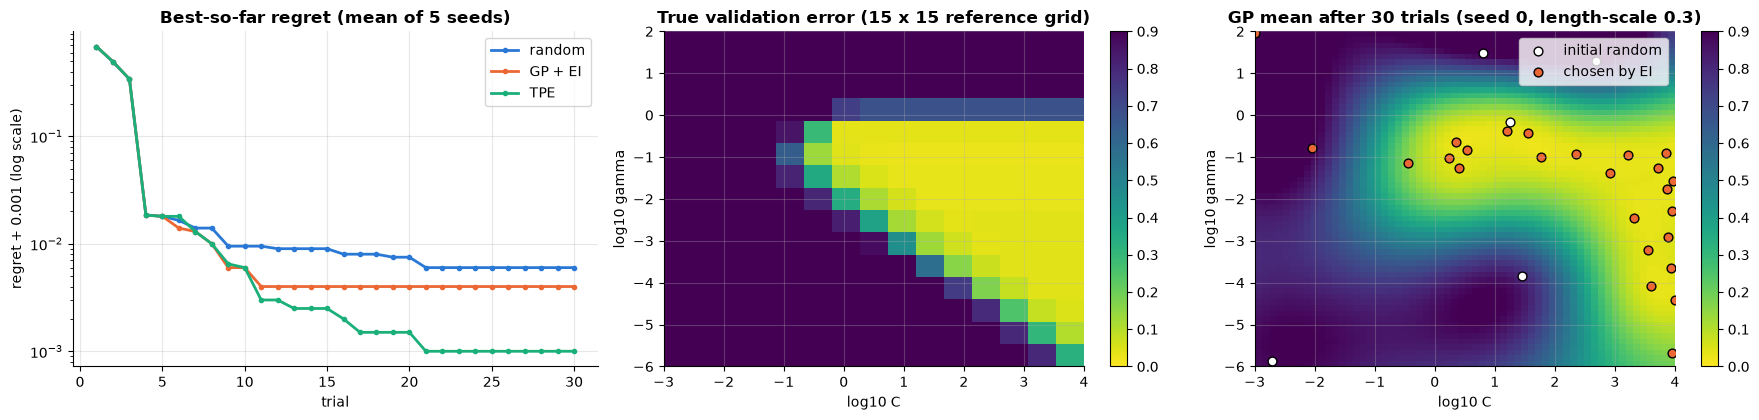

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.3))
for (name, cs), col in zip(curves.items(), PALETTE):
    ax[0].semilogy(range(1, 31), np.mean(cs, 0) + 1e-3, "o-", ms=3, color=col, label=name)
ax[0].set_xlabel("trial"); ax[0].set_ylabel("regret + 0.001 (log scale)"); ax[0].set_title("Best-so-far regret (mean of 5 seeds)")
ax[0].legend()

ext = [LO[0], HI[0], LO[1], HI[1]]
im = ax[1].imshow(true_grid, origin="lower", extent=ext, aspect="auto", cmap="viridis_r", vmin=0, vmax=0.9)
ax[1].set_title("True validation error (15 x 15 reference grid)"); fig.colorbar(im, ax=ax[1])
Z_, y_ = runs[("GP + EI", 0)]
g1 = np.linspace(0, 1, 60); Gq = np.array([(a, b) for b in g1 for a in g1])
mu_q, sd_q, ell = gp_fit_predict(Z_, y_, Gq)
im2 = ax[2].imshow(mu_q.reshape(60, 60), origin="lower", extent=ext, aspect="auto", cmap="viridis_r", vmin=0, vmax=0.9)
pts = LO + Z_ * (HI - LO)
ax[2].scatter(pts[:5, 0], pts[:5, 1], c="white", edgecolor="k", s=40, label="initial random")
ax[2].scatter(pts[5:, 0], pts[5:, 1], c=PALETTE[1], edgecolor="k", s=40, label="chosen by EI")
fig.colorbar(im2, ax=ax[2]); ax[2].set_title(f"GP mean after 30 trials (seed 0, length-scale {ell})")
for a in ax[1:]:
    a.set_xlabel("log10 C"); a.set_ylabel("log10 gamma")
ax[2].legend(loc="upper right"); plt.tight_layout(); plt.show()

**What just happened?** In this wide box most settings are useless (the dark plateau of the reference grid, about 69% of the box, where the SVM is no better than guessing), and the good region (yellow) is a wedge with a sharp diagonal edge. Random search keeps wasting trials on the plateau. GP + EI and TPE learn where the good wedge is from the first few trials and concentrate their trials inside it (orange points in the right plot), so they reach low regret in fewer trials and end lower after 10, 20 and 30 trials; compare the table. The GP's mean surface after 30 trials is a recognisable sketch of the true landscape, although it is only accurate where it sampled. With 5 seeds the comparison is still noisy; the advantage of model-based search grows when each trial is expensive.

**Complexity.** A GP surrogate costs **O(n³)** per refit for n trials (fine for hundreds of trials, which is the regime of expensive objectives). TPE costs O(n) per candidate and handles categorical and conditional parameters naturally, which is why Optuna and Hyperopt use it by default. BOHB (Falkner et al., 2018) combines TPE-style models with Hyperband budgets.

## 5. Early stopping and learning-curve extrapolation

> 💬 **In plain English:** if a run looks hopeless after a few epochs, stop it and save the time.

**Intuition.** For iterative learners (neural networks, boosting, SGD), the validation curve after a few epochs predicts where it will end. Fit a parametric curve to the first epochs, **extrapolate**, and stop runs whose predicted final score cannot beat the best so far (Domhan, Springenberg & Hutter, 2015, used an ensemble of such curves). A common simple model is the power law
$$\text{acc}(t) = a - b\,t^{-c}, \qquad a = \text{asymptote}.$$

8 MLP learning curves x 30 epochs in 2.5s
epochs used with early stopping: 165 of 240; best final accuracy kept: 0.9725 (true best: 0.9725)


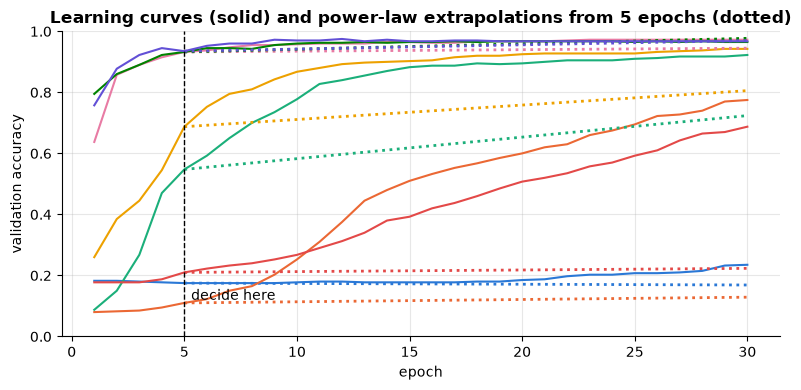

,config,acc @ epoch 5,predicted @ 30,actual @ 30,stopped early?
0,"lr=0.0001, alpha=0.0001, h=32",0.175,0.169,0.235,False
1,"lr=0.0003, alpha=0.001, h=64",0.110,0.129,0.775,True
2,"lr=0.001, alpha=0.0001, h=64",0.548,0.724,0.922,False
3,"lr=0.003, alpha=0.01, h=32",0.688,0.806,0.942,True
4,"lr=0.01, alpha=0.0001, h=64",0.932,0.945,0.972,False
5,"lr=0.03, alpha=0.001, h=32",0.932,0.977,0.965,False
6,"lr=0.1, alpha=0.0001, h=64",0.935,0.970,0.968,False
7,"lr=0.001, alpha=0.1, h=16",0.210,0.223,0.688,True


In [10]:
def power_law(t, a, b, c):
    return a - b * t ** (-c)

lr_cfgs = [{"learning_rate_init": lr, "alpha": al, "hidden_layer_sizes": (h,)}
           for lr, al, h in [(1e-4, 1e-4, 32), (3e-4, 1e-3, 64), (1e-3, 1e-4, 64), (3e-3, 1e-2, 32),
                             (1e-2, 1e-4, 64), (3e-2, 1e-3, 32), (1e-1, 1e-4, 64), (1e-3, 1e-1, 16)]]
EPOCHS, SEEN = 30, 5
curves_lc = []
t0 = time.time()
for cfg in lr_cfgs:
    m = MLPClassifier(random_state=0, **cfg)
    acc_t = []
    for ep in range(EPOCHS):
        m.partial_fit(X_tr, y_tr, classes=np.arange(10))
        acc_t.append(m.score(X_val, y_val))
    curves_lc.append(np.array(acc_t))
print(f"8 MLP learning curves x {EPOCHS} epochs in {time.time() - t0:.1f}s")

preds = []
for c in curves_lc:
    t = np.arange(1, SEEN + 1)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            p, _ = curve_fit(power_law, t, c[:SEEN], p0=[c[SEEN - 1], 0.5, 0.5],
                             bounds=([0, -2, 0.01], [1, 2, 3]), maxfev=5000)
        preds.append(min(power_law(EPOCHS, *p), 1.0))
    except RuntimeError:
        preds.append(c[SEEN - 1])                                     # fall back to the last observed value
lc = pd.DataFrame({"config": [f"lr={c['learning_rate_init']:g}, alpha={c['alpha']:g}, h={c['hidden_layer_sizes'][0]}" for c in lr_cfgs],
                   f"acc @ epoch {SEEN}": [c[SEEN - 1] for c in curves_lc],
                   f"predicted @ {EPOCHS}": preds, f"actual @ {EPOCHS}": [c[-1] for c in curves_lc]})

# Early-stopping rule: run configs one by one; stop a run at epoch 5 if its prediction is below the best final so far
best_final, epochs_used, stopped = -1, 0, []
for c, pr in zip(curves_lc, preds):
    if pr < best_final - 0.005:
        epochs_used += SEEN; stopped.append(True)
    else:
        epochs_used += EPOCHS; stopped.append(False); best_final = max(best_final, c[-1])
lc["stopped early?"] = stopped
print(f"epochs used with early stopping: {epochs_used} of {len(lr_cfgs) * EPOCHS}; "
      f"best final accuracy kept: {best_final:.4f} (true best: {max(c[-1] for c in curves_lc):.4f})")

fig, ax = plt.subplots(figsize=(8, 4))
for c, pr, col in zip(curves_lc, preds, PALETTE * 2):
    ax.plot(range(1, EPOCHS + 1), c, color=col, lw=1.5)
    ax.plot([SEEN, EPOCHS], [c[SEEN - 1], pr], ":", color=col)
ax.axvline(SEEN, color="k", lw=1, ls="--"); ax.text(SEEN + 0.3, 0.12, "decide here")
ax.set_xlabel("epoch"); ax.set_ylabel("validation accuracy"); ax.set_ylim(0, 1)
ax.set_title("Learning curves (solid) and power-law extrapolations from 5 epochs (dotted)")
plt.tight_layout(); plt.show()
lc.round(3)

**What just happened?** After only 5 of 30 epochs, the extrapolated curves separate the hopeless runs (learning rate far too small, or regularisation far too strong) from the promising ones. The stopping rule used 165 of 240 epochs (about a third saved) and still kept the best run. Extrapolation is imperfect: runs with a late "take-off" are underestimated. Here the run with lr = 0.003 and alpha = 0.01 was predicted to reach 0.81 but would have reached 0.94, beating the best run finished at that point, and it was stopped anyway. Practical systems therefore add a safety margin, or use rank-based pruning such as the **median rule** (stop if worse than the median of other runs at the same epoch) or Hyperband/ASHA with epochs as the budget.

## 6. Ensemble selection (Caruana et al., 2004)

> 💬 **In plain English:** instead of keeping only the single best model, blend a few good ones.

**Intuition.** A search produces dozens of decent models. Instead of throwing all but one away, combine them. **Ensemble selection** greedily builds an ensemble from the library of models: start empty; repeatedly add (with replacement) the model whose addition most improves the **validation** score of the averaged predicted probabilities. Allowing repeats gives models integer weights. Auto-sklearn and AutoGluon both use this idea (AutoGluon adds multi-layer stacking).

In [11]:
# A library: 30 random configurations from the CASH space, each refit on the full training set
r_lib = np.random.default_rng(11)
library = []
t0 = time.time()
for _ in range(30):
    cfg = sample_config(r_lib)
    m = build_model(cfg)
    if cfg["algo"] == "svc":                                        # SVC has no predict_proba: calibrate its scores
        m = CalibratedClassifierCV(m, ensemble=False)
    m.fit(X_tr, y_tr)
    library.append((cfg, m.predict_proba(X_val), m.predict_proba(X_te)))
print(f"library of {len(library)} models built in {time.time() - t0:.1f}s")

def acc_of(P, y):
    return (P.argmax(1) == y).mean()                               # accuracy of averaged class probabilities

def ensemble_selection(P_val, y, n_steps=25):
    chosen, current = [], np.zeros_like(P_val[0])
    for step in range(n_steps):
        scores = [acc_of((current * len(chosen) + P) / (len(chosen) + 1), y) for P in P_val]
        best = int(np.argmax(scores))                              # ties: lowest index (deterministic)
        chosen.append(best)
        current = (current * (len(chosen) - 1) + P_val[best]) / len(chosen)
    return chosen

P_val = [v for _, v, _ in library]; P_te = [t for _, _, t in library]
single_val = [acc_of(P, y_val) for P in P_val]
best_single = int(np.argmax(single_val))
chosen = ensemble_selection(P_val, y_val)
ens_val = acc_of(np.mean([P_val[i] for i in chosen], 0), y_val)
ens_te = acc_of(np.mean([P_te[i] for i in chosen], 0), y_te)
weights = pd.Series(chosen).value_counts()
print("ensemble members (library index: times chosen):", dict(weights))
print("their algorithms:", {i: library[i][0]["algo"] for i in weights.index})
pd.DataFrame({"validation acc": [single_val[best_single], ens_val],
              "test acc": [acc_of(P_te[best_single], y_te), ens_te]},
             index=["best single model", "ensemble selection"]).round(4)

library of 30 models built in 6.5s
ensemble members (library index: times chosen): {3: np.int64(10), 2: np.int64(7), 23: np.int64(5), 21: np.int64(2), 16: np.int64(1)}
their algorithms: {3: 'svc', 2: 'rf', 23: 'svc', 21: 'logreg', 16: 'knn'}


,validation acc,test acc
best single model,0.995,0.995
ensemble selection,0.995,0.995


**What just happened?** The greedy procedure mixed several algorithm families (SVMs, a random forest, logistic regression, k-NN) with integer weights (how often each was chosen). On **validation** the ensemble is at least as good as the best single model by construction (the first step picks that model); here it only ties it, on validation and on test, because on an easy dataset like digits the best SVM is already at 99.5%. In general the honest comparison is the **test** column, since part of any validation gain is over-fitting to the 400 validation examples. On harder tabular problems, with cross-validated (out-of-fold) predictions as auto-sklearn and AutoGluon use, ensemble selection gives reliable gains.

## 7. Meta-learning warm starts

> 💬 **In plain English:** start the search from what worked on similar datasets before.

**Intuition.** If you have tuned models on many past datasets, a new dataset that "looks like" an old one probably likes similar configurations. Describe each dataset with **meta-features** and start the search from the best configurations of the most similar past datasets (Feurer et al., 2015, in auto-sklearn).

| Meta-feature type | Examples |
|---|---|
| simple | number of samples, features, classes; class entropy |
| statistical | mean absolute correlation between features, skewness |
| **landmarkers** | accuracy of very cheap models: 1-nearest-neighbour, a decision stump, naive Bayes |

We build 18 synthetic "past" datasets from three families (noisy high-dimensional linear problems, multi-cluster problems, and two-moons problems with a few noise features), measure a portfolio of 7 configurations on each, and do **leave-one-dataset-out**: for each held-out dataset, recommend the best configuration of its nearest neighbour in meta-feature space, and measure the **regret** (best possible accuracy minus the accuracy of the recommendation).

In [12]:
portfolio = {"logreg C=1": LogisticRegression(C=1, max_iter=500), "logreg C=0.1": LogisticRegression(C=0.1, max_iter=500),
             "logreg C=0.01": LogisticRegression(C=0.01, max_iter=500), "svc rbf": SVC(),
             "knn k=5": KNeighborsClassifier(5), "knn k=25": KNeighborsClassifier(25),
             "rf": RandomForestClassifier(30, random_state=0, n_jobs=1)}

def meta_features(X, y):
    cv = StratifiedKFold(3, shuffle=True, random_state=0)
    p = np.bincount(y) / len(y)
    C = np.corrcoef(X.T); off = C[~np.eye(len(C), dtype=bool)]
    return {"log n": np.log(len(X)), "log d": np.log(X.shape[1]), "classes": len(p),
            "class entropy": -(p * np.log(p)).sum(), "mean |corr|": np.abs(off).mean(),
            "1-NN acc": cross_val_score(KNeighborsClassifier(1), X, y, cv=cv).mean(),          # landmarkers
            "stump acc": cross_val_score(DecisionTreeClassifier(max_depth=1), X, y, cv=cv).mean(),
            "naive Bayes acc": cross_val_score(GaussianNB(), X, y, cv=cv).mean()}

def make_task(r, family):
    from sklearn.datasets import make_moons
    if family == "linear, high-dim, noisy":
        X, y = make_classification(n_samples=150, n_features=int(r.choice([50, 100])), n_informative=3, n_redundant=0,
                                   n_clusters_per_class=1, flip_y=0.05, random_state=int(r.integers(1e6)))
    elif family == "multi-cluster":
        X, y = make_classification(n_samples=300, n_features=10, n_informative=8, n_redundant=0, n_clusters_per_class=4,
                                   class_sep=2.0, random_state=int(r.integers(1e6)))
    else:
        X2, y = make_moons(300, noise=float(r.choice([0.1, 0.2])), random_state=int(r.integers(1e6)))
        X = np.c_[X2, r.normal(size=(300, int(r.integers(0, 3)))) * 0.5]
    return (X - X.mean(0)) / X.std(0), y

r_meta = np.random.default_rng(3)
families = [["linear, high-dim, noisy", "multi-cluster", "two moons + noise"][i % 3] for i in range(18)]
MF, PERF = [], []
t0 = time.time()
for fam in families:
    Xd, yd = make_task(r_meta, fam)
    MF.append(meta_features(Xd, yd))
    cv = StratifiedKFold(3, shuffle=True, random_state=1)
    PERF.append({k: cross_val_score(m, Xd, yd, cv=cv).mean() for k, m in portfolio.items()})
MF, PERF = pd.DataFrame(MF), pd.DataFrame(PERF)
print(f"18 datasets x 7 configs (3-fold CV) in {time.time() - t0:.1f}s")
print("mean CV accuracy per family:")
print(PERF.assign(family=families).groupby("family").mean().round(3).to_string())

Zmf = ((MF - MF.mean()) / MF.std()).values                          # standardised meta-features
rows = []
for i in range(len(MF)):
    others = [j for j in range(len(MF)) if j != i]                  # leave-one-dataset-out
    nn_j = others[int(np.argmin(np.linalg.norm(Zmf[others] - Zmf[i], axis=1)))]
    best_overall = PERF.iloc[others].rank(axis=1, ascending=False).mean().idxmin()   # best average rank elsewhere
    best_here = PERF.iloc[i].max()
    rows.append({"regret: random config": best_here - PERF.iloc[i].mean(),
                 "regret: single best overall config": best_here - PERF.iloc[i][best_overall],
                 "regret: nearest dataset's best config": best_here - PERF.iloc[i][PERF.iloc[nn_j].idxmax()]})
print()
print(pd.DataFrame(rows).mean().round(4).to_string())

18 datasets x 7 configs (3-fold CV) in 6.2s
mean CV accuracy per family:
                         logreg C=1  logreg C=0.1  logreg C=0.01  svc rbf  knn k=5  knn k=25     rf
family                                                                                             
linear, high-dim, noisy       0.789         0.810          0.794    0.804    0.681     0.707  0.853
multi-cluster                 0.776         0.776          0.778    0.941    0.941     0.920  0.909
two moons + noise             0.866         0.860          0.852    0.926    0.966     0.916  0.959

regret: random config                    0.0768
regret: single best overall config       0.0469
regret: nearest dataset's best config    0.0259


**What just happened?** The families prefer different configurations (see the per-family table): the random forest is strong almost everywhere, but the multi-cluster tasks favour the SVM and k-NN, and the high-dimensional linear tasks punish k-NN. Choosing a configuration at random loses several points of accuracy on average. A single "best on average" default already does much better. Copying the best configuration of the **most similar past dataset** (by meta-features, including cheap landmarkers) roughly halves the regret of the single default, because it adapts to the kind of dataset. With only 18 past datasets and noisy meta-features the recommendation is sometimes wrong (auto-sklearn's meta-learning used 140 past datasets). In a real system these recommendations are only the **starting points** of a search (warm starts), so a bad recommendation costs little.

## 8. A toy neural architecture search

> 💬 **In plain English:** let the robot also choose the shape of the neural network, and count what that costs.

**Neural architecture search (NAS)** treats the network's structure (depth, width, activation, dropout, connections) as hyperparameters. The three ingredients are a **search space**, a **search strategy** (random search, evolution, RL, gradient-based relaxations such as DARTS) and a **performance-estimation strategy** (full training, early stopping, weight sharing). Random search is a surprisingly strong baseline for NAS (Li & Talwalkar, 2019). Below: random search over small MLPs on digits, with **cost accounting**.

14 architectures trained in 4.6s total (3.2s of training)


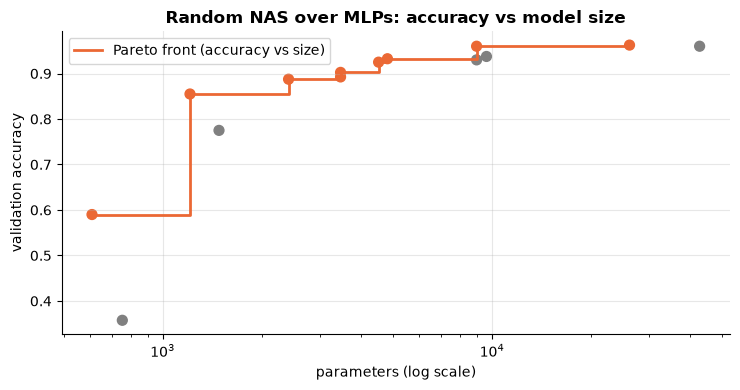

,depth,width,act,dropout,params,FLOPs/example,train seconds,val acc,Pareto-optimal
4,1,8,relu,0.2,610,1184,0.086,0.590,True
2,3,8,relu,0.0,754,1440,0.154,0.357,False
8,1,16,tanh,0.0,1210,2368,0.079,0.855,True
13,2,16,tanh,0.2,1482,2880,0.187,0.775,False
6,1,32,relu,0.2,2410,4736,0.187,0.887,True
1,2,32,tanh,0.0,3466,6784,0.175,0.892,True
3,2,32,relu,0.0,3466,6784,0.127,0.902,True
10,3,32,tanh,0.0,4522,8832,0.153,0.925,True
5,1,64,tanh,0.0,4810,9472,0.116,0.933,True
9,2,64,tanh,0.0,8970,17664,0.157,0.960,True


In [13]:
Xt_tr, yt_tr = torch.tensor(X_tr, dtype=torch.float32), torch.tensor(y_tr)
Xt_val, yt_val = torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val)

def make_mlp(depth, width, act, dropout):
    layers, d_in = [], 64
    for _ in range(depth):
        layers += [nn.Linear(d_in, width), nn.ReLU() if act == "relu" else nn.Tanh(), nn.Dropout(dropout)]
        d_in = width
    layers.append(nn.Linear(d_in, 10))
    return nn.Sequential(*layers)

def flops_per_example(model):
    return sum(2 * m.in_features * m.out_features for m in model if isinstance(m, nn.Linear))   # multiply-adds x 2

r_nas = np.random.default_rng(5)
nas_rows = []
t_all = time.time()
for trial in range(14):
    arch = {"depth": int(r_nas.integers(1, 4)), "width": int(r_nas.choice([8, 16, 32, 64, 128])),
            "act": str(r_nas.choice(["relu", "tanh"])), "dropout": float(r_nas.choice([0.0, 0.2]))}
    torch.manual_seed(trial)
    model = make_mlp(**arch)
    opt = torch.optim.Adam(model.parameters(), lr=3e-3)
    t0 = time.perf_counter()
    for ep in range(60):                                           # full-batch training: tiny data
        model.train(); loss = nn.functional.cross_entropy(model(Xt_tr), yt_tr)
        opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        acc = (model(Xt_val).argmax(1) == yt_val).float().mean().item()
    nas_rows.append({**arch, "params": sum(p.numel() for p in model.parameters()), "FLOPs/example": flops_per_example(model),
                     "train seconds": time.perf_counter() - t0, "val acc": acc})
nas = pd.DataFrame(nas_rows).sort_values("params")
nas["Pareto-optimal"] = nas["val acc"] > nas["val acc"].cummax().shift(fill_value=-1)     # better than every smaller model
print(f"14 architectures trained in {time.time() - t_all:.1f}s total ({nas['train seconds'].sum():.1f}s of training)")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(nas["params"], nas["val acc"], c=[PALETTE[1] if p else "grey" for p in nas["Pareto-optimal"]], s=50)
po = nas[nas["Pareto-optimal"]]
ax.step(po["params"], po["val acc"], where="post", color=PALETTE[1], label="Pareto front (accuracy vs size)")
ax.set_xscale("log"); ax.set_xlabel("parameters (log scale)"); ax.set_ylabel("validation accuracy")
ax.set_title("Random NAS over MLPs: accuracy vs model size"); ax.legend(); plt.tight_layout(); plt.show()
nas.round(3)

**What just happened?** Random search over 14 small MLPs shows the usual picture: very narrow networks underfit, and beyond a moderate size, extra parameters buy little accuracy. The **Pareto front** (orange) lists the architectures that no smaller model beats; picking from it is how you trade accuracy against latency or memory. Every row reports its cost (parameters, FLOPs per example, training time), which is what a NAS paper should report too.

For scale: the original RL-based NAS (Zoph & Le, 2017) used 800 GPUs for about four weeks; weight-sharing methods such as ENAS and gradient-based DARTS cut the search to around a GPU-day, at the price of noisier performance estimates. On a small budget, a well-designed search space plus random search or Hyperband is a strong baseline.

## 9. Pitfalls: validation overfitting, nested CV, budget reporting

> 💬 **In plain English:** trying many settings on the same check data fools you; measure honestly and report the effort.

### 9.1 Overfitting the validation set
Every configuration you evaluate on the same validation set is a chance to get lucky. Pick the best of many, and its validation score is **optimistically biased** (the "winner's curse"). The extreme case: labels that are **pure noise**, so the true accuracy of every model is 50%.

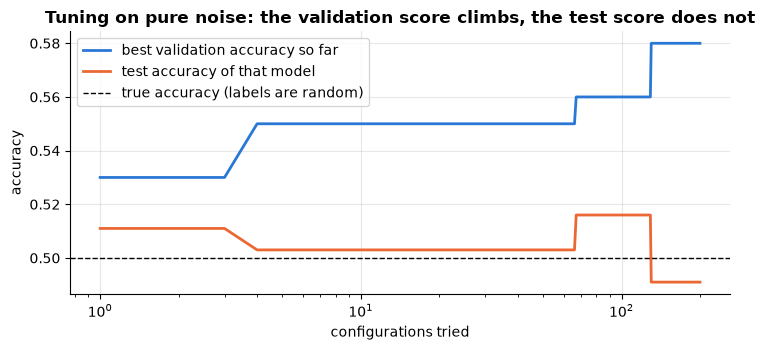

after 200 configs: best validation accuracy 0.58, its test accuracy 0.491


In [14]:
r9 = np.random.default_rng(9)
Xn = r9.normal(size=(1400, 20)); yn = r9.integers(0, 2, 1400)          # random labels: nothing to learn
Xn_tr, yn_tr, Xn_val, yn_val, Xn_te, yn_te = Xn[:300], yn[:300], Xn[300:400], yn[300:400], Xn[400:], yn[400:]
best_val, best_test, trace9 = -1, None, []
for trial in range(200):
    k = int(r9.integers(1, 40)); feats = r9.choice(20, int(r9.integers(2, 21)), replace=False)
    m = KNeighborsClassifier(k).fit(Xn_tr[:, feats], yn_tr)
    v = m.score(Xn_val[:, feats], yn_val)
    if v > best_val:
        best_val, best_test = v, m.score(Xn_te[:, feats], yn_te)
    trace9.append((best_val, best_test))
trace9 = np.array(trace9)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(range(1, 201), trace9[:, 0], label="best validation accuracy so far")
ax.plot(range(1, 201), trace9[:, 1], label="test accuracy of that model")
ax.axhline(0.5, ls="--", color="k", lw=1, label="true accuracy (labels are random)")
ax.set_xscale("log"); ax.set_xlabel("configurations tried"); ax.set_ylabel("accuracy"); ax.legend()
ax.set_title("Tuning on pure noise: the validation score climbs, the test score does not"); plt.tight_layout(); plt.show()
print(f"after 200 configs: best validation accuracy {trace9[-1, 0]:.2f}, its test accuracy {trace9[-1, 1]:.3f}")

### 9.2 Nested cross-validation
If hyperparameters are tuned by cross-validation, the best CV score is optimistic for the same reason. **Nested CV** wraps the whole tuning procedure inside an outer CV loop: the inner loop picks hyperparameters on the outer-training folds only, and the outer folds measure the tuned procedure on data it never saw. Use it to *report* performance (especially on small data); the final model is then tuned once on all the data.

In [15]:
rows = []
t0 = time.time()
for seed in range(4):
    Xs_, ys_ = make_classification(n_samples=120, n_features=30, n_informative=4, flip_y=0.1, random_state=seed)
    grid = {"C": np.logspace(-2, 3, 6), "gamma": np.logspace(-4, 1, 6)}
    inner = StratifiedKFold(4, shuffle=True, random_state=seed); outer = StratifiedKFold(4, shuffle=True, random_state=100 + seed)
    gs = GridSearchCV(SVC(), grid, cv=inner).fit(Xs_, ys_)
    nested = cross_val_score(GridSearchCV(SVC(), grid, cv=inner), Xs_, ys_, cv=outer).mean()
    rows.append({"seed": seed, "non-nested (best inner CV score)": gs.best_score_, "nested CV estimate": nested})
nest = pd.DataFrame(rows).set_index("seed")
nest.loc["mean"] = nest.mean()
print(f"nested vs non-nested CV in {time.time() - t0:.1f}s")
nest[["non-nested (best inner CV score)", "nested CV estimate"]].round(3)

nested vs non-nested CV in 12.6s


,non-nested (best inner CV score),nested CV estimate
seed,,
0,0.617,0.592
1,0.800,0.750
2,0.850,0.817
3,0.808,0.800
mean,0.769,0.740


**What just happened?** On pure noise, the best validation accuracy climbs well above 50% as more configurations are tried, while the test accuracy of the chosen model stays around 50%: the "improvement" was luck. On a small real-looking dataset, the non-nested score (the best of 36 grid points' CV scores) is higher than the nested estimate in every seed; the nested number is the honest one.

### 9.3 Report your compute budget
A search result is only meaningful together with its cost. Here is this notebook's own log of model fits:

In [16]:
log = pd.DataFrame(SEARCH_LOG)
budget_table = log.groupby("tag").agg(fits=("val_acc", "size"), full_fit_equivalents=("n_train", lambda s: s.sum() / N_TRAIN),
                                      cpu_seconds=("seconds", "sum"), best_val_acc=("val_acc", "max"))
budget_table.round(3)

,fits,full_fit_equivalents,cpu_seconds,best_val_acc
tag,,,,
BO-reference-grid,225,45.000,3.834,0.972
BO-study,450,90.000,7.197,0.978
grid,16,16.000,2.839,0.990
hyperband,69,15.659,2.706,0.995
random,48,48.000,5.605,0.995
random-full,16,16.000,1.507,0.980


**What a good tuning report contains:** the search space (ranges, scales, conditionals), the search method and its settings, the number of configurations and the total compute (CPU/GPU hours, or full-fit equivalents as above), the number of random seeds, how the final model was selected (which split), and a test score measured **once** on data never used for selection. Comparing method A tuned for 100 trials with method B tuned for 10 is a common, unfair comparison.

> ⚠️ **Common mistake:** tuning on the test set "just once more". Every look at the test set used for a decision turns it into a validation set. Keep a final hold-out you touch only at the end.

## 10. Method comparison

| Method | Uses past trials? | Uses cheap partial runs? | Parallel? | Handles conditional/categorical? | Best when |
|---|---|---|---|---|---|
| Grid search | no | no | trivially | awkward | 1–2 knobs, final fine sweep |
| Random search | no | no | trivially | yes | baseline; many knobs, cheap trials |
| Successive halving / Hyperband / ASHA | no | **yes** | yes (ASHA: asynchronous) | yes | budget knob exists (epochs, data, trees) |
| GP-based BO + EI | **yes** | no | needs batch tricks | poorly (needs special kernels) | expensive trials, ≤ ~20 continuous knobs |
| TPE | **yes** | no | moderately | **yes** | mixed spaces; Optuna/Hyperopt default |
| BOHB | yes | yes | yes | yes | best of both: model-based + budgets |
| Meta-learning warm start | from past *datasets* | – | – | yes | many similar past tasks |
| Ensemble selection | reuses all trials | – | – | – | final step of an AutoML run |

## 11. 🔗 How this connects to modern AI

- **Tuning LLM training**: full-size LLM runs are too expensive to tune directly, so teams tune on small proxy models and transfer hyperparameters with scaling laws or parameterisations designed for transfer (such as μP, "maximal update parametrization"); the learning-rate sweep on small models is exactly the low-budget rung of successive halving.
- **Tools you will meet**: Optuna (TPE + pruners such as median and Hyperband/ASHA), Ray Tune (ASHA, PBT), Hyperopt, SMAC (random-forest surrogate BO), auto-sklearn (meta-learning + BO + ensemble selection) and AutoGluon (stacked ensembles); see [`01_automl`](01_automl.ipynb) and [`15_MLOps/10_advanced_experiment_tracking`](../10_advanced_experiment_tracking.ipynb) for logging sweeps.
- **NAS in practice**: EfficientNet's scaling was found by a NAS-style search; hardware-aware NAS designs mobile networks; for LLMs, architecture search is mostly done by small-scale ablations plus scaling-law extrapolation, which is learning-curve extrapolation at a grand scale.
- **LLM agents for AutoML**: research systems use LLMs to propose configurations or write pipelines, but they still need the same disciplined evaluation: fixed budgets, held-out tests, and nested validation.

## 12. Recap

- AutoML solves **CASH**: a tree-structured search over algorithms and their conditional hyperparameters. Use **log scales** for scale parameters and check that the best trials are not at the edge of the space.
- **Random search beats grid search** when only a few knobs matter (low effective dimensionality).
- **Successive halving** spends little on bad configurations; **Hyperband** hedges the n-vs-r trade-off with several brackets; ASHA makes it asynchronous.
- **Bayesian optimisation** fits a surrogate (GP or TPE densities) and chooses the next trial by **expected improvement**; it shines when trials are expensive.
- **Learning-curve extrapolation** and pruning rules stop hopeless runs early.
- **Ensemble selection** turns the search's by-products into a better model; judge it on held-out data.
- **Meta-learning** warm-starts the search from similar past datasets.
- **NAS** is hyperparameter search over architectures; always report its cost.
- Beware the **winner's curse**: report a once-touched test score or a **nested CV** estimate, together with the **compute budget**.

## Practice problems

**1. (Easy, conceptual)** Why should the learning rate be searched on a log scale? What fraction of uniform samples on [10⁻⁵, 10⁻¹] fall below 10⁻³?
<details><summary>Show solution</summary>

The effect of the learning rate is multiplicative: going from 10⁻⁴ to 10⁻³ changes training as much as going from 10⁻² to 10⁻¹, so each decade deserves equal attention. Uniformly on [10⁻⁵, 10⁻¹], the fraction below 10⁻³ is (10⁻³ − 10⁻⁵)/(10⁻¹ − 10⁻⁵) ≈ **0.0099**, about 1%, although two of the four decades lie there. Log-uniform sampling gives 50%.

</details>

**2. (Easy, coding)** Write a function that returns the Hyperband schedule (brackets of (n configs, budget) rungs) and check it against the table in Li et al. for R = 81, η = 3.
<details><summary>Show solution</summary>

```python
import numpy as np
def hyperband_schedule(R, eta=3):
    """List of brackets; each bracket is a list of (n_configs, budget) rungs."""
    s_max = int(np.floor(np.log(R) / np.log(eta) + 1e-9))
    B = (s_max + 1) * R
    out = []
    for s in range(s_max, -1, -1):
        n = int(np.ceil(B / R * eta ** s / (s + 1)))
        r = R * eta ** (-s)
        out.append([(int(n * eta ** (-i)), r * eta ** i) for i in range(s + 1)])
    return out
```
For R = 81, η = 3 the brackets start with 81, 34, 15, 8 and 5 configurations; the s = 3 bracket is 34 configs @ 3 → 11 @ 9 → 3 @ 27 → 1 @ 81, as in the paper.

</details>

**3. (Medium, coding)** Implement expected improvement in closed form and verify it with a Monte Carlo estimate.
<details><summary>Show solution</summary>

```python
import numpy as np
from scipy.stats import norm
def ei_closed_form(mu, sd, f_best):
    z = (f_best - mu) / sd
    return (f_best - mu) * norm.cdf(z) + sd * norm.pdf(z)
def ei_monte_carlo(mu, sd, f_best, n=400000, seed=0):
    f = np.random.default_rng(seed).normal(mu, sd, n)
    return np.maximum(f_best - f, 0).mean()
```
The closed form follows from integrating `max(f* − f, 0)` against the Gaussian density of f.

</details>

**4. (Medium, coding)** Simulate successive halving on 27 configurations whose observed score at rung i is the final score plus noise with standard deviation 0.05/3ⁱ. How often does SH keep one of the 3 truly best configurations?
<details><summary>Show solution</summary>

```python
import numpy as np
def successive_halving_oracle(final_scores, noise_at_budget, eta=3, n_rungs=4, seed=0):
    """Simulated SH: at rung i a config's observed score is its final score plus noise that shrinks with budget."""
    r = np.random.default_rng(seed)
    alive = np.arange(len(final_scores))
    for i in range(n_rungs):
        obs = final_scores[alive] + r.normal(0, noise_at_budget(i), len(alive))
        if len(alive) == 1:
            break
        alive = alive[np.argsort(-obs)[:max(1, len(alive) // eta)]]
    return alive[0]
```
In this setting SH keeps a top-3 configuration in more than 90% of 200 simulations, while spending most of its budget on only a few configurations.

</details>

**5. (Medium, conceptual)** Why does ensemble selection add models **with replacement**, and why is its validation score optimistic?
<details><summary>Show solution</summary>

With replacement, a strong model can be added several times, which gives integer weights and lets the ensemble behave like a weighted average rather than a plain average of a fixed set (Caruana et al. also found it reduces over-fitting compared with selection without replacement). Its validation score is optimistic because the members and weights were chosen to maximise that very score; an unbiased estimate needs a separate test set or cross-validated (out-of-fold) predictions.

</details>

**6. (Medium, conceptual)** A paper reports that its model beats a baseline by 0.4% accuracy. The authors tuned their model with 200 Optuna trials and used the default hyperparameters for the baseline. What is wrong, and what would you ask for?
<details><summary>Show solution</summary>

The comparison is confounded by tuning budget: the gain may come from the 200 trials, not the method. Ask for the baseline tuned with the same search space style and budget, the number of seeds and confidence intervals, a test set not used for selection (or nested CV), and the compute cost of both.

</details>

**7. (Hard, coding project)** Implement **ASHA** (asynchronous successive halving): workers request jobs; a configuration is promoted from rung k to k+1 as soon as it is in the top 1/η of the configurations *completed so far* at rung k; otherwise a new configuration is started at rung 0. Simulate 4 workers with random job durations and compare time-to-good-result with synchronous SH.
<details><summary>Show solution</summary>

Sketch: keep, for each rung, a list of (config, score) results. When a worker becomes free: scan rungs from the top; if some config at rung k is in the top ⌊|results_k|/η⌋ and not yet promoted, promote it (train at budget r·η^(k+1)); otherwise sample a new config at rung 0. Simulate time with a priority queue of job finish times (duration ∝ budget × random factor). ASHA never waits for a rung to fill, so workers stay busy; it may promote a few configs that synchronous SH would not, but reaches good configurations much sooner in wall-clock time (Li et al., 2020).

</details>

## Further reading
- F. Hutter, L. Kotthoff, J. Vanschoren (eds.), *Automated Machine Learning: Methods, Systems, Challenges* (Springer, 2019), ch. 1 (HPO), ch. 2 (meta-learning), ch. 3 (NAS). Free online at automl.org.
- J. Bergstra & Y. Bengio (2012), "Random Search for Hyper-Parameter Optimization", *JMLR*; J. Bergstra et al. (2011), "Algorithms for Hyper-Parameter Optimization" (TPE).
- L. Li et al. (2018), "Hyperband: A Novel Bandit-Based Approach to Hyperparameter Optimization", *JMLR*; S. Falkner et al. (2018), "BOHB".
- J. Snoek, H. Larochelle, R. Adams (2012), "Practical Bayesian Optimization of Machine Learning Algorithms".
- R. Caruana et al. (2004), "Ensemble Selection from Libraries of Models"; M. Feurer et al. (2015), "Efficient and Robust Automated Machine Learning" (auto-sklearn).
- T. Elsken, J. H. Metzen, F. Hutter (2019), "Neural Architecture Search: A Survey", *JMLR*.
- G. C. Cawley & N. L. C. Talbot (2010), "On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation", *JMLR*.

## Next notebook
⬅️ Previous: [AutoML tools tour](01_automl.ipynb) · ➡️ Next: [Federated learning](../09_federated_learning/01_federated_learning.ipynb)